In [56]:
%cd /home/mojtaba.kananisarche/

/home/mojtaba.kananisarche


In [57]:
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib import colormaps
import time
import math
import datetime
import numpy as np

In [58]:
pvt = pd.DataFrame()
pvt_rt_directory_path = "/work/long_lab/Mojtaba/data/DROZY/data/original/pvt-rt"
with open("/work/long_lab/Mojtaba/data/DROZY/data/original/KSS.txt", "r") as f:
    lines = f.readlines()
    for subject_idx, kss_scores in enumerate(lines, start=1):
        for session_idx, kss_score in enumerate(kss_scores.split(), start=1):
            pvt_file_name = f"{subject_idx}-{session_idx}.csv"
            pvt_file_path = os.path.join(pvt_rt_directory_path, pvt_file_name)
            if not os.path.exists(pvt_file_path):
                continue
            
            df = pd.read_csv(pvt_file_path, 
                    skiprows=0, 
                    delimiter=";", 
                    header=None, 
                    names=["stimuli", "response"]).map(lambda x: pd.to_datetime(x, format="%Y-%m-%d_%H.%M.%S.%f"))
            start_time = df.iloc[0,0]
            df = df.drop(0).reset_index(drop=True).map(lambda x: x-start_time)
            df["reaction_time"] = df["response"] - df["stimuli"]
            df = df.map(lambda x: x.total_seconds())
            df["plot"] = df.apply(lambda x: (x["stimuli"],
                                            x["reaction_time"]), axis=1)
            df["subject_idx"] = int(subject_idx)
            df["session_idx"] = int(session_idx)
            df["kss_score"] = int(kss_score)
            df = df[["subject_idx", "session_idx", "kss_score", "stimuli", "response", "reaction_time", "plot"]]
            
            pvt = pd.concat([pvt, df], ignore_index=True)

In [59]:
pvt = pvt.sort_values(["kss_score", "subject_idx", "session_idx", "stimuli"]).reset_index(drop=True)

In [60]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

def get_color_from_colormap(palette_name: str, value: float, min_val: float, max_val: float):
    """
    Returns a color from a matplotlib colormap based on a value within a range.

    Parameters:
    - palette_name (str): Name of the matplotlib colormap (e.g., 'viridis', 'plasma').
    - value (float): The value to map.
    - min_val (float): The minimum of the value range.
    - max_val (float): The maximum of the value range.

    Returns:
    - (r, g, b): Tuple of RGB values in [0, 1].
    """
    if min_val == max_val:
        raise ValueError("min_val and max_val must be different to define a range.")
    
    # Normalize the value to [0, 1]
    norm_value = np.clip((value - min_val) / (max_val - min_val), 0, 1)

    # Get the colormap
    colormap = colormaps[palette_name]

    # Apply colormap
    rgba = colormap(norm_value)

    # Return RGB (drop alpha)
    return rgba[:3]

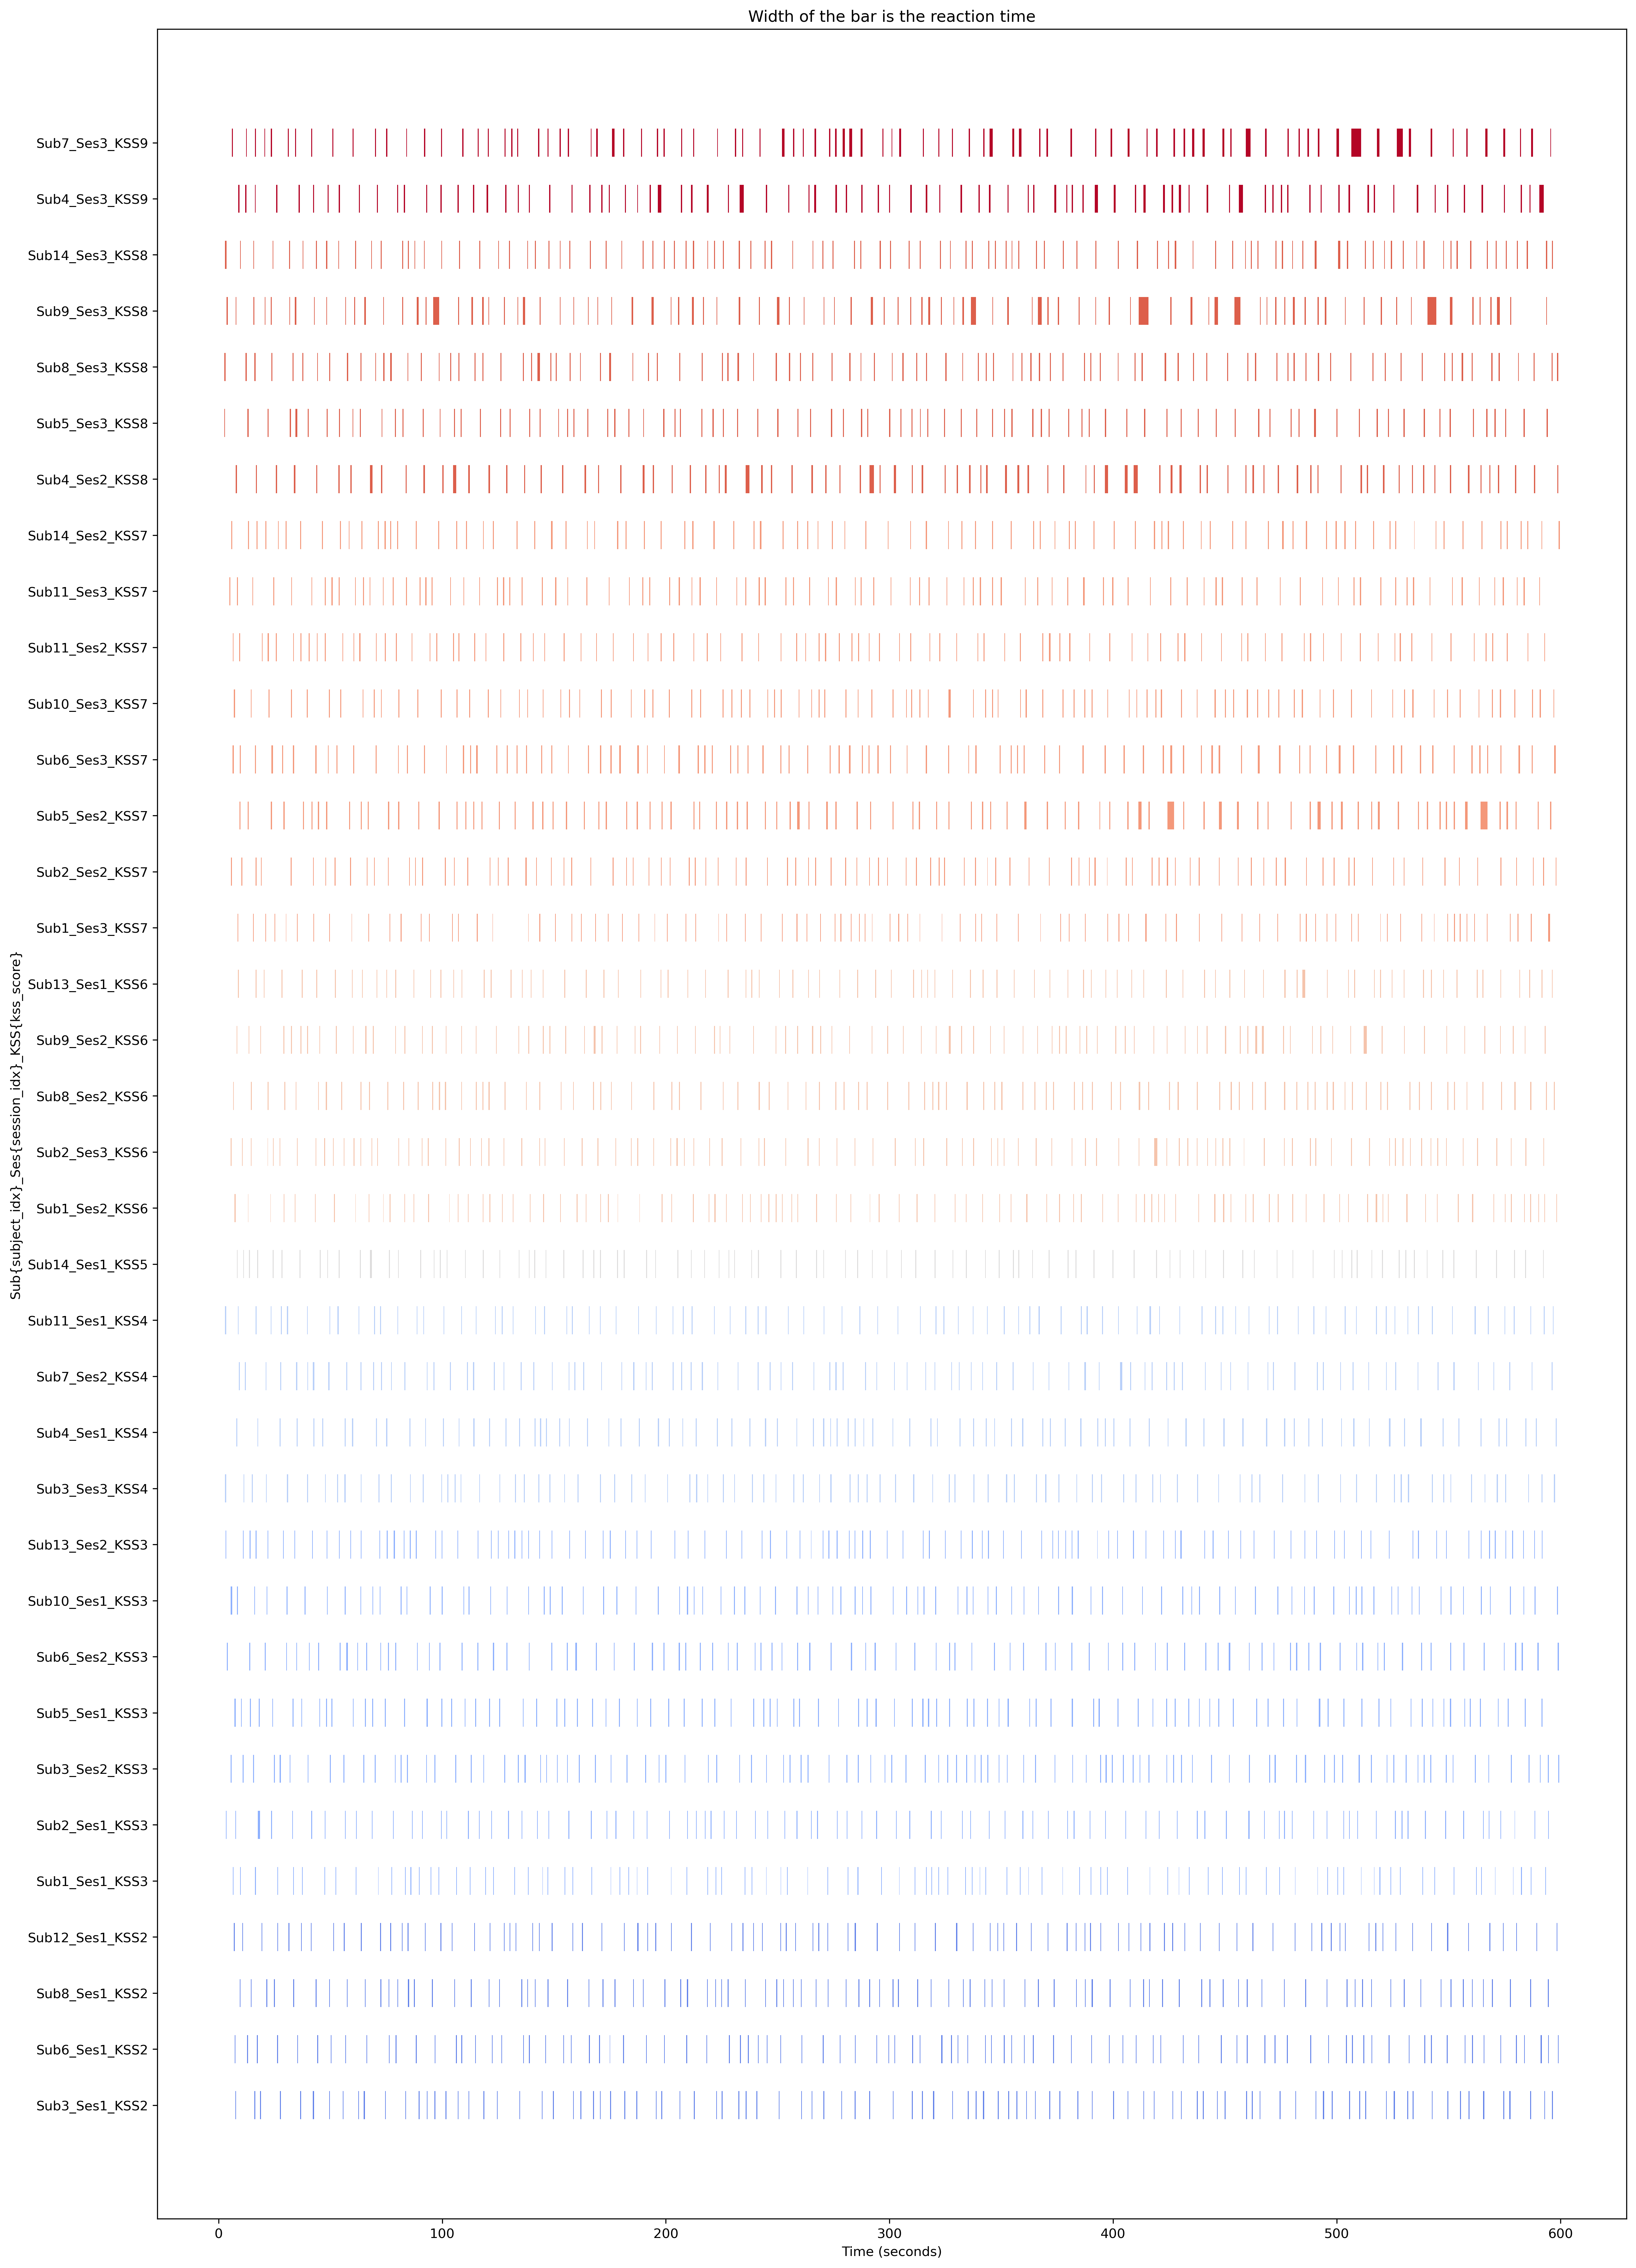

In [61]:
fig, ax = plt.subplots(figsize=(20, 30), dpi=300)
yticks = []
yticklabels = []

for idx, row in pvt[["subject_idx", "session_idx"]].drop_duplicates().reset_index(drop=True).iterrows():
    subject_idx, session_idx = row["subject_idx"], row["session_idx"]
    df = pvt[(pvt["subject_idx"] == subject_idx) & (pvt["session_idx"] == session_idx)]
    barh = ax.broken_barh(df["plot"], (idx, 0.5), 
                    facecolors=get_color_from_colormap("coolwarm", value=df['kss_score'].iloc[0], min_val=1, max_val=9),
                    label=f"{idx}")
    yticks.append(idx+0.25)
    yticklabels.append(f"Sub{subject_idx}_Ses{session_idx}_KSS{df['kss_score'].iloc[0]}")

_ = ax.set_yticks(yticks)
_ = ax.set_yticklabels(yticklabels)
_ = ax.set_ylabel("Sub{subject_idx}_Ses{session_idx}_KSS{kss_score}")
_ = ax.set_xlabel("Time (seconds)")
_ = ax.set_title("Width of the bar is the reaction time")

In [62]:
pvt_avg = pvt.groupby(["subject_idx", "session_idx"]).aggregate({"kss_score": "mean","reaction_time": "mean"}).sort_values("reaction_time")

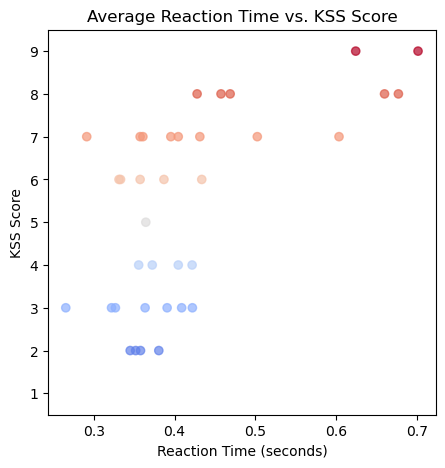

In [63]:
fig, ax = plt.subplots(figsize=(5, 5), dpi=100)
_ = ax.scatter(pvt_avg["reaction_time"], pvt_avg["kss_score"], marker='o',ls='', c=[get_color_from_colormap("coolwarm", value=row["kss_score"], min_val=1, max_val=9)+(0.7,) for idx, row in pvt_avg.iterrows()])
_ = ax.set_ylim(0.5,9.5)
_ = ax.set_xlabel("Reaction Time (seconds)")
_ = ax.set_ylabel("KSS Score")
_ = ax.set_title("Average Reaction Time vs. KSS Score")

Text(0.5, 1.0, 'Reaction Time vs. KSS Score')

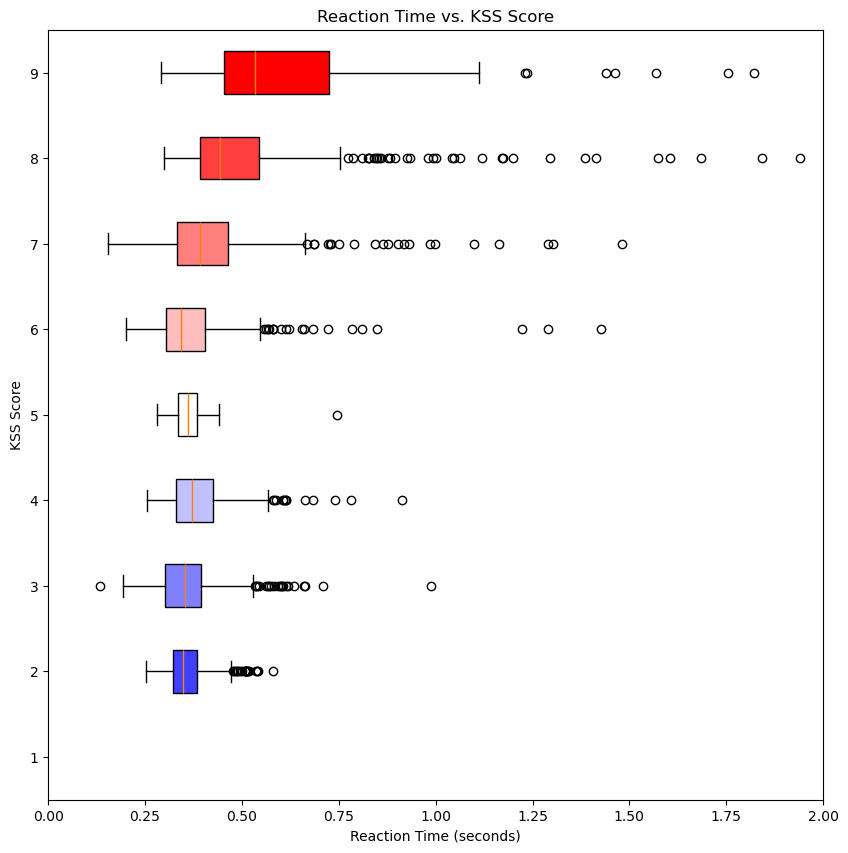

In [64]:
fig, ax = plt.subplots(figsize=(10, 10), dpi=100)
data = []

for kss_score in range(1, 10):
    df = pvt[(pvt["kss_score"] == kss_score)]
    rt = df["reaction_time"].tolist()
    record = {
        "kss_score": kss_score,
        "rt": rt,
        "avg": sum(rt)/len(rt) if len(rt) > 0 else 0,
        "median": np.median(rt) if len(rt) > 0 else 0,
        "yticklabel": kss_score
    }
    data.append(record)

data = sorted(data, key=lambda x: (x["kss_score"]))
for i in data:
    i["ytick"] = data.index(i)+0.25

bp = ax.boxplot([i['rt'] for i in data], 
           positions=[i['ytick'] for i in data], 
           tick_labels=[i['yticklabel'] for i in data],
           widths=0.5, 
           patch_artist=True, 
           boxprops=dict(facecolor='C0'), 
           vert=False,
          )
colors = [get_color_from_colormap("bwr", value=i["kss_score"], min_val=1, max_val=9) for i in data]
for box, color in zip(bp['boxes'], colors):
    box.set_facecolor(color)
ax.set_xlim(0,2)
ax.set_ylabel("KSS Score")
ax.set_xlabel("Reaction Time (seconds)")
ax.set_title("Reaction Time vs. KSS Score")
# ax.set_yticks(yticks)
# ax.set_yticklabels(yticklabels)

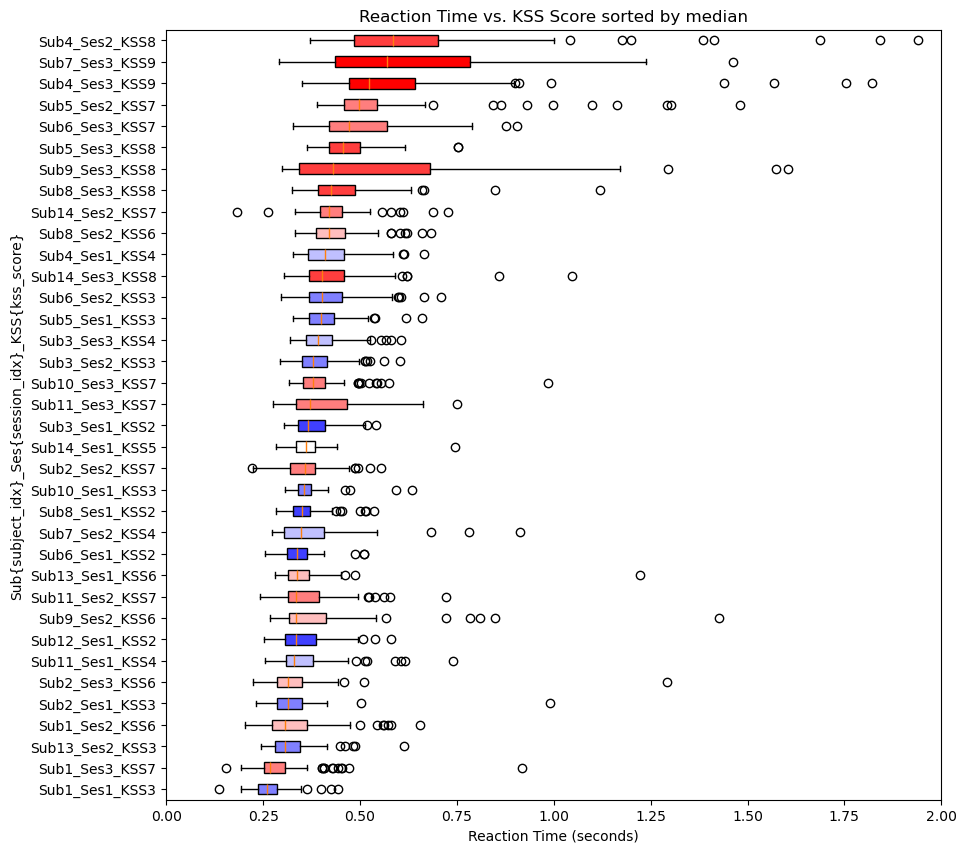

In [65]:
fig, ax = plt.subplots(figsize=(10, 10), dpi=100)
data = []

for idx, row in pvt[["subject_idx", "session_idx"]].drop_duplicates().reset_index(drop=True).iterrows():
    subject_idx, session_idx = row["subject_idx"], row["session_idx"]
    df = pvt[(pvt["subject_idx"] == subject_idx) & (pvt["session_idx"] == session_idx)]
    rt = df["reaction_time"].tolist()
    record = {
        "subject_idx": subject_idx,
        "session_idx": session_idx,
        "kss_score": df["kss_score"].iloc[0],
        "rt": rt,
        "avg": sum(rt)/len(rt),
        "median": np.median(rt),
        "yticklabel": f"Sub{subject_idx}_Ses{session_idx}_KSS{df['kss_score'].iloc[0]}"
    }
    data.append(record)

data = sorted(data, key=lambda x: x["median"])
for i in data:
    i["ytick"] = data.index(i)+0.25

bp = ax.boxplot([i['rt'] for i in data], 
           positions=[i['ytick'] for i in data], 
           tick_labels=[i['yticklabel'] for i in data],
           widths=0.5, 
           patch_artist=True, 
           boxprops=dict(facecolor='C0'), 
           vert=False,
          )
colors = [get_color_from_colormap("bwr", value=i["kss_score"], min_val=1, max_val=9) for i in data]
for box, color in zip(bp['boxes'], colors):
    box.set_facecolor(color)
ax.set_xlim(0,2)
_ = ax.set_ylabel("Sub{subject_idx}_Ses{session_idx}_KSS{kss_score}")
_ = ax.set_xlabel("Reaction Time (seconds)")
_ = ax.set_title("Reaction Time vs. KSS Score sorted by median")
# ax.set_yticks(yticks)
# ax.set_yticklabels(yticklabels)

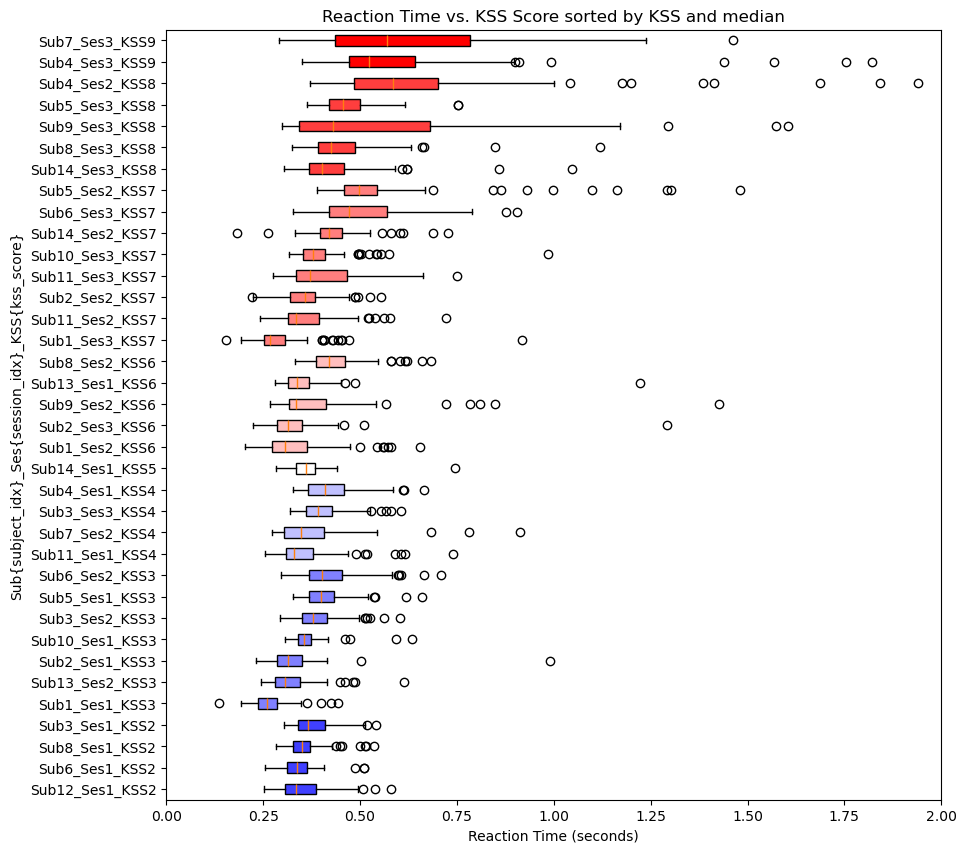

In [66]:
fig, ax = plt.subplots(figsize=(10, 10), dpi=100)
data = []

for idx, row in pvt[["subject_idx", "session_idx"]].drop_duplicates().reset_index(drop=True).iterrows():
    subject_idx, session_idx = row["subject_idx"], row["session_idx"]
    df = pvt[(pvt["subject_idx"] == subject_idx) & (pvt["session_idx"] == session_idx)]
    rt = df["reaction_time"].tolist()
    record = {
        "subject_idx": subject_idx,
        "session_idx": session_idx,
        "kss_score": df["kss_score"].iloc[0],
        "rt": rt,
        "avg": sum(rt)/len(rt),
        "median": np.median(rt),
        "yticklabel": f"Sub{subject_idx}_Ses{session_idx}_KSS{df['kss_score'].iloc[0]}"
    }
    data.append(record)

data = sorted(data, key=lambda x: (x["kss_score"], x["median"]))
for i in data:
    i["ytick"] = data.index(i)+0.25

bp = ax.boxplot([i['rt'] for i in data], 
           positions=[i['ytick'] for i in data], 
           tick_labels=[i['yticklabel'] for i in data],
           widths=0.5, 
           patch_artist=True, 
           boxprops=dict(facecolor='C0'), 
           vert=False,
          )
colors = [get_color_from_colormap("bwr", value=i["kss_score"], min_val=1, max_val=9) for i in data]
for box, color in zip(bp['boxes'], colors):
    box.set_facecolor(color)
ax.set_xlim(0,2)
_ = ax.set_ylabel("Sub{subject_idx}_Ses{session_idx}_KSS{kss_score}")
_ = ax.set_xlabel("Reaction Time (seconds)")
_ = ax.set_title("Reaction Time vs. KSS Score sorted by KSS and median")
# ax.set_yticks(yticks)
# ax.set_yticklabels(yticklabels)

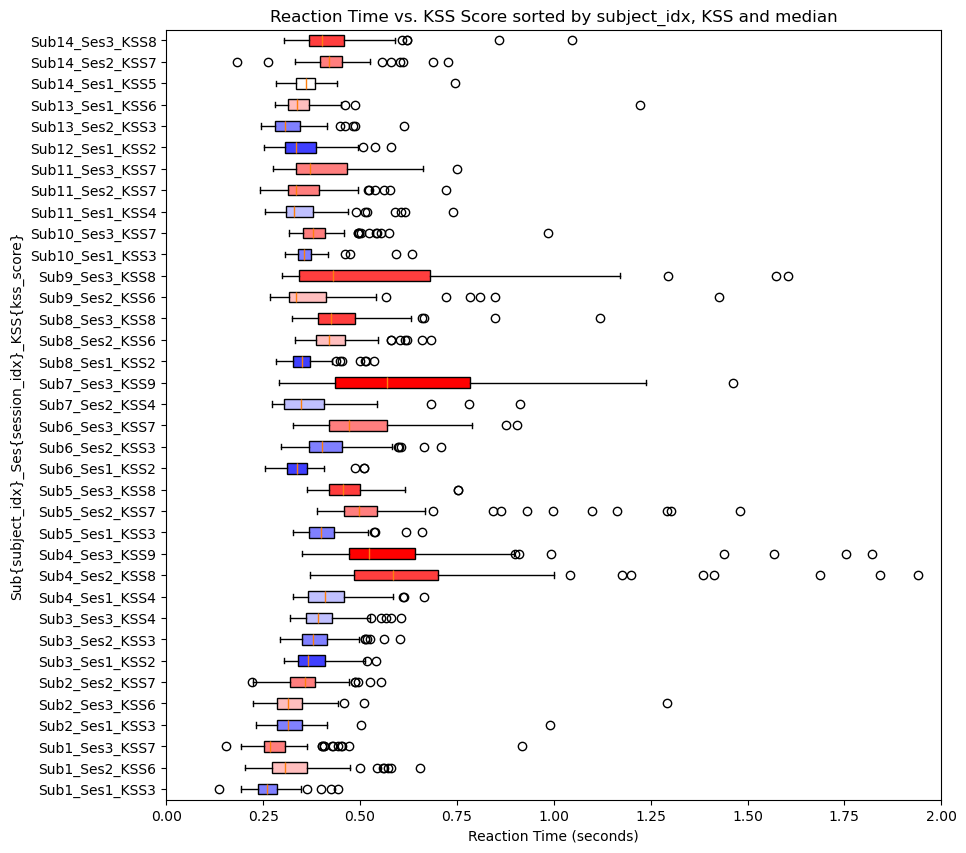

In [67]:
fig, ax = plt.subplots(figsize=(10, 10), dpi=100)
data = []

for idx, row in pvt[["subject_idx", "session_idx"]].drop_duplicates().reset_index(drop=True).iterrows():
    subject_idx, session_idx = row["subject_idx"], row["session_idx"]
    df = pvt[(pvt["subject_idx"] == subject_idx) & (pvt["session_idx"] == session_idx)]
    rt = df["reaction_time"].tolist()
    record = {
        "subject_idx": subject_idx,
        "session_idx": session_idx,
        "kss_score": df["kss_score"].iloc[0],
        "rt": rt,
        "avg": sum(rt)/len(rt),
        "median": np.median(rt),
        "yticklabel": f"Sub{subject_idx}_Ses{session_idx}_KSS{df['kss_score'].iloc[0]}"
    }
    data.append(record)

data = sorted(data, key=lambda x: (x["subject_idx"], x["kss_score"], x["median"]))
for i in data:
    i["ytick"] = data.index(i)+0.25

bp = ax.boxplot([i['rt'] for i in data], 
           positions=[i['ytick'] for i in data], 
           tick_labels=[i['yticklabel'] for i in data],
           widths=0.5, 
           patch_artist=True, 
           boxprops=dict(facecolor='C0'), 
           vert=False,
          )
colors = [get_color_from_colormap("bwr", value=i["kss_score"], min_val=1, max_val=9) for i in data]
for box, color in zip(bp['boxes'], colors):
    box.set_facecolor(color)
ax.set_xlim(0,2)
_ = ax.set_ylabel("Sub{subject_idx}_Ses{session_idx}_KSS{kss_score}")
_ = ax.set_xlabel("Reaction Time (seconds)")
_ = ax.set_title("Reaction Time vs. KSS Score sorted by subject_idx, KSS and median")
# ax.set_yticks(yticks)
# ax.set_yticklabels(yticklabels)

In [68]:
pvt = pvt.sort_values(by=["subject_idx", "session_idx", "kss_score", "stimuli"]).reset_index(drop=True)

In [69]:
import pandas as pd

# Assuming df is your original DataFrame with columns:
# 'subject_idx', 'session_idx', 'reaction_time'

# 1. Sort by subject/session/time (if needed for ordering)
df_sorted = pvt.sort_values(by=['subject_idx', 'session_idx', 'kss_score', 'stimuli'])

# 2. Group and aggregate reaction_time values into a list
grouped = df_sorted.groupby(['subject_idx', 'session_idx', 'kss_score'])['reaction_time'].apply(list)

# 3. Convert each list to a row: each reaction time becomes a column
wide_df = grouped.apply(pd.Series).reset_index()

# 4. Optional: rename columns
wide_df.columns = ['subject_idx', 'session_idx', 'kss_score'] + [f'reaction_time_{i}' for i in range(wide_df.shape[1] - 3)]

In [70]:
wide_df.head()

,subject_idx,session_idx,kss_score,reaction_time_0,reaction_time_1,reaction_time_2,reaction_time_3,reaction_time_4,reaction_time_5,reaction_time_6,...,reaction_time_96,reaction_time_97,reaction_time_98,reaction_time_99,reaction_time_100,reaction_time_101,reaction_time_102,reaction_time_103,reaction_time_104,reaction_time_105
0,1,1,3,0.313,0.285,0.362,0.242,0.278,0.324,0.246,...,0.264,0.264,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,6,0.465,0.202,0.228,0.256,0.273,0.272,0.419,...,0.332,0.268,0.249,0.393,NaN,NaN,NaN,NaN,NaN,NaN
2,1,3,7,0.267,0.247,0.253,0.291,0.214,0.257,0.208,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,1,3,0.312,0.292,0.989,0.391,0.283,0.309,0.251,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,2,7,0.331,0.365,0.365,0.346,0.346,0.350,0.360,...,0.412,0.344,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


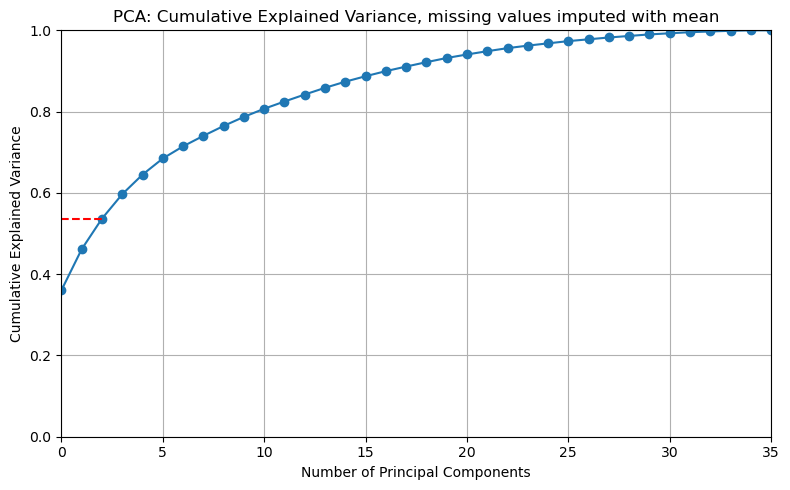

In [71]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Step 1: Select only reaction_time columns
reaction_time_cols = [col for col in wide_df.columns if col.startswith('reaction_time_')]
X = wide_df[reaction_time_cols]

# Step 2: Handle missing values (optional: fill with mean or drop)
X = X.fillna(X.mean()) 

# Step 3: Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Fit PCA
pca = PCA()
pca.fit(X_scaled)

# Step 5: Plot cumulative explained variance
cumulative_variance = pca.explained_variance_ratio_.cumsum()

plt.figure(figsize=(8, 5))
plt.plot(cumulative_variance, marker='o')
# add a point at second principal component, draw a horizontal line connecting it to the y-axis and write the exact cumulative variance explained in until that point
plt.axhline(y=cumulative_variance[2], xmax=2/35, color='red', linestyle='--')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA: Cumulative Explained Variance, missing values imputed with mean')
plt.xlim(0, 35)
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()

In [72]:
# Project the scaled data onto the first 2 principal components
X_pca = pca.transform(X_scaled)

# Extract just the first two components
pc_df = pd.DataFrame(X_pca[:, :3], columns=['PC1', 'PC2', 'PC3'])

# Optionally, join with identifiers
pc_df = pd.concat([wide_df[['subject_idx', 'session_idx', 'kss_score']], pc_df], axis=1)

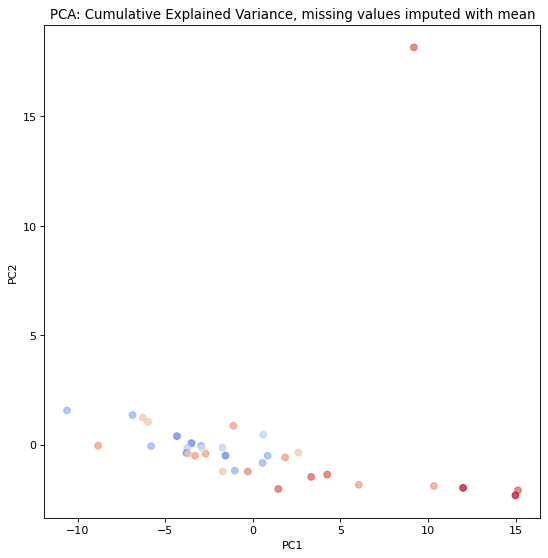

In [73]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=80)
_ = ax.scatter(pc_df["PC1"], pc_df["PC2"], marker='o',ls='', c=[get_color_from_colormap("coolwarm", value=row["kss_score"], min_val=1, max_val=9)+(0.7,) for _, row in pc_df.iterrows()])
_ = ax.set_xlabel("PC1")
_ = ax.set_ylabel("PC2")
_ = ax.set_title("PCA: Cumulative Explained Variance, missing values imputed with mean")

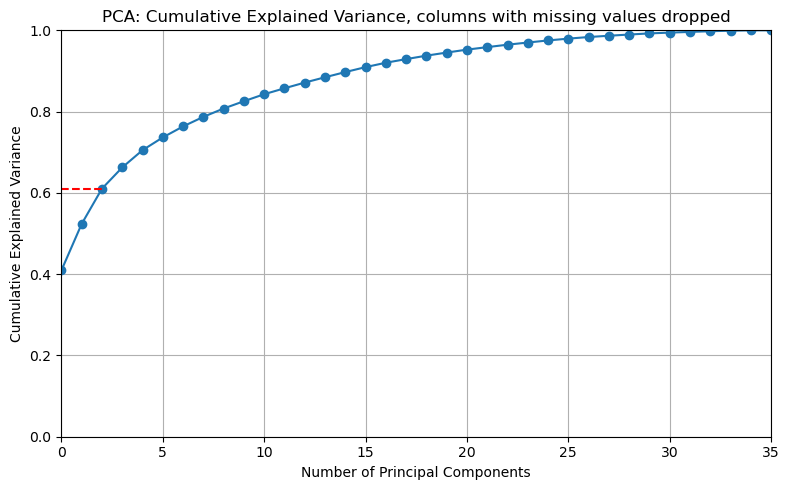

In [74]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Step 1: Select only reaction_time columns
reaction_time_cols = [col for col in wide_df.columns if col.startswith('reaction_time_')]
X = wide_df[reaction_time_cols]

# Step 2: Handle missing values (optional: fill with mean or drop)
# X = X.fillna(X.mean())  # Or: X = X.dropna()
X = X.dropna(axis=1)

# Step 3: Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Fit PCA
pca = PCA()
pca.fit(X_scaled)

# Step 5: Plot cumulative explained variance
cumulative_variance = pca.explained_variance_ratio_.cumsum()

plt.figure(figsize=(8, 5))
plt.plot(cumulative_variance, marker='o')
plt.axhline(y=cumulative_variance[2], xmax=2/35, color='red', linestyle='--')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA: Cumulative Explained Variance, columns with missing values dropped')
plt.xlim(0, 35)
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()

In [75]:
# Project the scaled data onto the first 2 principal components
X_pca = pca.transform(X_scaled)

# Extract just the first two components
pc_df = pd.DataFrame(X_pca[:, :3], columns=['PC1', 'PC2', 'PC3'])

# Optionally, join with identifiers
pc_df = pd.concat([wide_df[['subject_idx', 'session_idx', 'kss_score']], pc_df], axis=1)

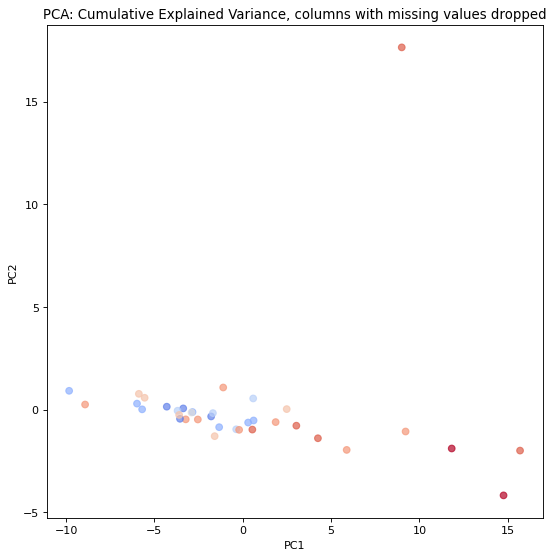

In [76]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=80)
_ = ax.scatter(pc_df["PC1"], pc_df["PC2"], marker='o',ls='', c=[get_color_from_colormap("coolwarm", value=row["kss_score"], min_val=1, max_val=9)+(0.7,) for _, row in pc_df.iterrows()])
_ = ax.set_xlabel("PC1")
_ = ax.set_ylabel("PC2")
_ = ax.set_title('PCA: Cumulative Explained Variance, columns with missing values dropped')